# Customer Churn Analytics Platform

## 03 — Exploratory Data Analysis

**Objective:**
Explore customer behavior, churn patterns, service usage, contract types, tenure, and revenue characteristics to identify meaningful business trends.

### Analysis Goals

* Analyze overall customer and churn distribution
* Explore churn by customer demographics
* Analyze churn by contract type
* Analyze churn by internet and additional services
* Explore payment method behavior
* Analyze churn across tenure groups
* Analyze monthly and total charges
* Identify high-risk customer segments
* Explore relationships between customer characteristics and churn
* Generate business-oriented insights for further analysis


In [3]:
# ============================================================
# IMPORT LIBRARIES
# ============================================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [4]:
# ============================================================
# VISUALIZATION THEME
# ============================================================

plt.style.use("dark_background")

sns.set_theme(
    style="darkgrid",
    context="notebook"
)

DARK_BG = "#0F172A"
CARD_BG = "#1E293B"
TEXT_COLOR = "#F8FAFC"
GRID_COLOR = "#334155"

plt.rcParams.update({
    "figure.facecolor": DARK_BG,
    "axes.facecolor": CARD_BG,
    "axes.edgecolor": GRID_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,
    "grid.color": GRID_COLOR,
    "text.color": TEXT_COLOR,
    "figure.titlesize": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 11
})

print("Visualization theme configured successfully.")

Visualization theme configured successfully.


In [5]:
# ============================================================
# LOAD CLEAN DATASET
# ============================================================

DATA_PATH = Path(
    "../data/processed/customer_churn_clean.csv"
)

df = pd.read_csv(DATA_PATH)

print("Clean dataset loaded successfully.")
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

Clean dataset loaded successfully.
Rows    : 7,043
Columns : 21


In [6]:
# ============================================================
# DATASET OVERVIEW
# ============================================================

print("=" * 60)
print("EDA DATASET OVERVIEW")
print("=" * 60)

print(f"Rows             : {len(df):,}")
print(f"Columns          : {len(df.columns):,}")
print(f"Unique Customers : {df['customerid'].nunique():,}")
print(f"Missing Values   : {df.isna().sum().sum():,}")
print(f"Duplicate Rows   : {df.duplicated().sum():,}")

EDA DATASET OVERVIEW
Rows             : 7,043
Columns          : 21
Unique Customers : 7,043
Missing Values   : 0
Duplicate Rows   : 0


In [7]:
# ============================================================
# CHURN OVERVIEW
# ============================================================

churn_counts = df["churn"].value_counts()

churn_summary = pd.DataFrame({
    "Customers": churn_counts,
    "Percentage": (
        churn_counts / len(df) * 100
    ).round(2)
})

churn_summary

,Customers,Percentage
churn,,
no,5174,73.46
yes,1869,26.54


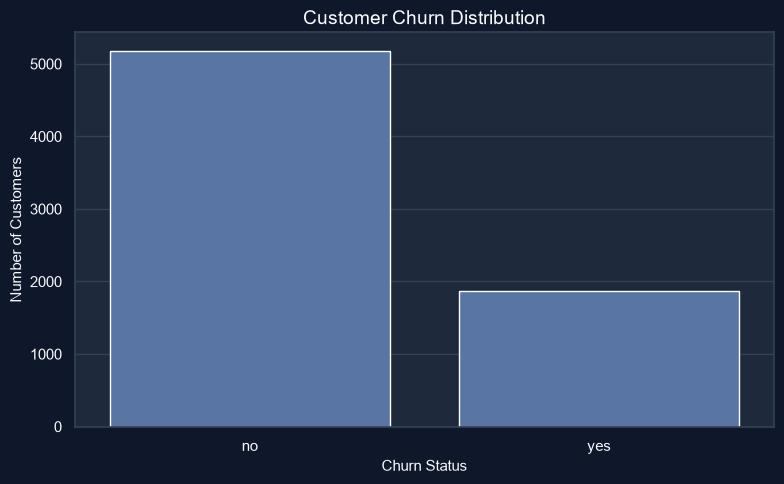

In [8]:
# ============================================================
# CHURN DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="churn"
)

ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

C:\Users\Kunde\AppData\Local\Temp\ipykernel_16872\1420487256.py:38: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([


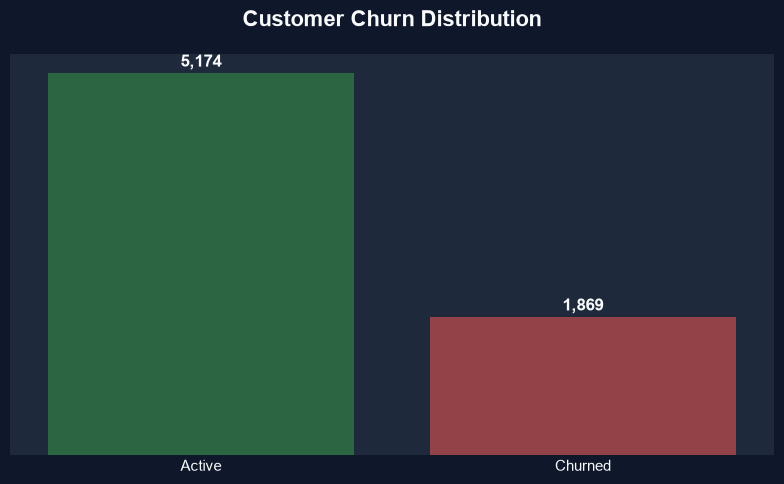

In [11]:
# ============================================================
# CELL 06 — CHURN DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="churn",
    hue="churn",
    palette={
        "no": "#216F3F",     # Active
        "yes": "#A1343C"     # Churned
    },
    legend=False,
    edgecolor="none",
    linewidth=0
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Customer Churn Distribution",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------

ax.set_xlabel("")
ax.set_ylabel("")

ax.set_xticklabels([
    "Active",
    "Churned"
])

# Remove Y-axis numbers
ax.set_yticks([])

# ------------------------------------------------------------
# REMOVE GRID & BORDERS
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# ------------------------------------------------------------
# VALUES ABOVE BARS
# ------------------------------------------------------------

for bar in ax.patches:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 40,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# OVERALL CHURN RATE
# ============================================================

churn_rate = (
    (df["churn"] == "yes").mean() * 100
)

print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 26.54%


In [ ]:
# ============================================================
# CHURN BY GENDER
# ============================================================

gender_churn = pd.crosstab(
    df["gender"],
    df["churn"],
    normalize="index"
) * 100

gender_churn.round(2)

churn,no,yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


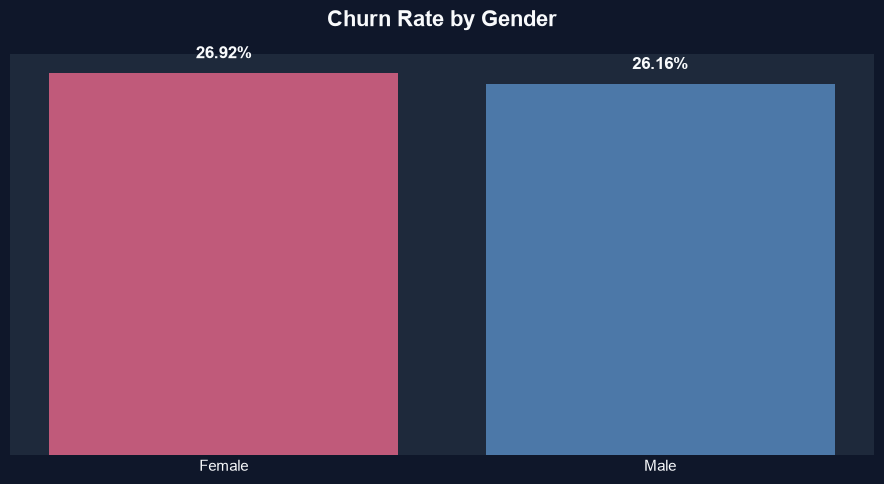

In [19]:
# ============================================================
# CELL 09 — GENDER CHURN CHART
# ============================================================

gender_churn = (
    df.groupby("gender")
      .agg(
          Customers=("customerid", "count"),
          Churned=("churn", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

gender_churn["Churn_Rate"] = (
    gender_churn["Churned"]
    / gender_churn["Customers"]
    * 100
)

# ------------------------------------------------------------
# STANDARD GENDER COLORS
# ------------------------------------------------------------

Gender_Colors = {
    "Female": "#C05A7A",
    "Male": "#4C78A8"
}

Bar_Colors = [
    Gender_Colors.get(gender, "#1F4E79")
    for gender in gender_churn["gender"]
]

# ------------------------------------------------------------
# CHART
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

ax = plt.gca()

bars = ax.bar(
    gender_churn["gender"],
    gender_churn["Churn_Rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Churn Rate by Gender",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# ------------------------------------------------------------
# AXIS
# ------------------------------------------------------------

ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])

# ------------------------------------------------------------
# REMOVE GRID & BORDERS
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# ------------------------------------------------------------
# VALUES ABOVE BARS
# ------------------------------------------------------------

for bar, rate in zip(
    bars,
    gender_churn["Churn_Rate"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CHURN BY SENIOR CITIZEN
# ============================================================

senior_churn = pd.crosstab(
    df["seniorcitizen"],
    df["churn"],
    normalize="index"
) * 100

senior_churn.round(2)

churn,no,yes
seniorcitizen,,
0,76.39,23.61
1,58.32,41.68


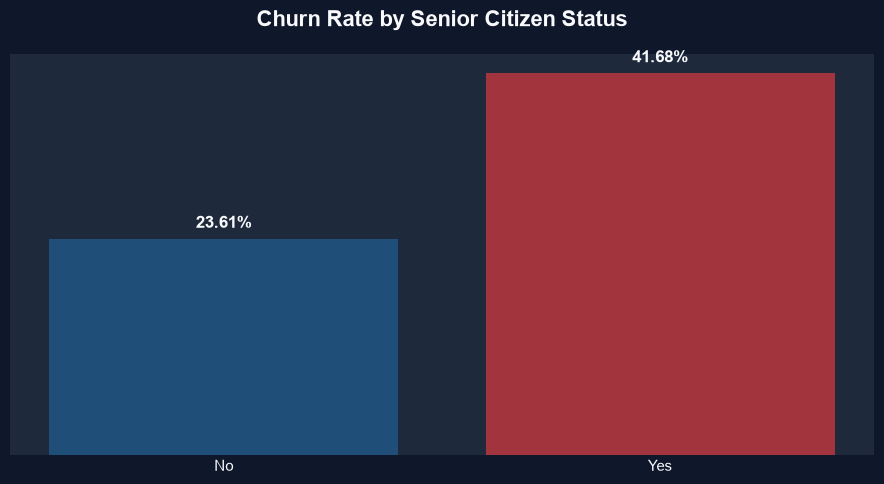

In [22]:
# ============================================================
# CELL 11 — SENIOR CITIZEN CHURN CHART
# ============================================================

senior_rate = (
    df.groupby("seniorcitizen")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
)

# Display labels
senior_rate["Senior_Citizen_Display"] = (
    senior_rate["seniorcitizen"]
    .map({
        0: "No",
        1: "Yes"
    })
)

# ------------------------------------------------------------
# STANDARD COLORS
# ------------------------------------------------------------

Senior_Colors = {
    "No": "#1F4E79",
    "Yes": "#A1343C"
}

Bar_Colors = [
    Senior_Colors.get(status, "#1F4E79")
    for status in senior_rate["Senior_Citizen_Display"]
]

# ------------------------------------------------------------
# CHART
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

ax = plt.gca()

bars = ax.bar(
    senior_rate["Senior_Citizen_Display"],
    senior_rate["churn_rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Churn Rate by Senior Citizen Status",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# ------------------------------------------------------------
# AXIS
# ------------------------------------------------------------

ax.set_xlabel("")
ax.set_ylabel("")

# Remove Y-axis numbers
ax.set_yticks([])

# ------------------------------------------------------------
# REMOVE GRID & BORDERS
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# ------------------------------------------------------------
# VALUES ABOVE BARS
# ------------------------------------------------------------

for bar, rate in zip(
    bars,
    senior_rate["churn_rate"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.tight_layout()
plt.show()

In [23]:
# ============================================================
# CHURN BY PARTNER
# ============================================================

partner_churn = (
    df.groupby("partner")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
)

partner_churn.round(2)

,partner,churn_rate
0,No,32.96
1,Yes,19.66


In [ ]:
# ============================================================
# CHURN BY DEPENDENTS
# ============================================================

dependents_churn = (
    df.groupby("dependents")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
)

dependents_churn.round(2)

,dependents,churn_rate
0,No,31.28
1,Yes,15.45


In [ ]:
# ============================================================
# CHURN BY CONTRACT
# ============================================================

contract_churn = (
    df.groupby("contract")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
    .sort_values("churn_rate", ascending=False)
)

contract_churn.round(2)

,contract,churn_rate
0,Month-to-month,42.71
1,One year,11.27
2,Two year,2.83


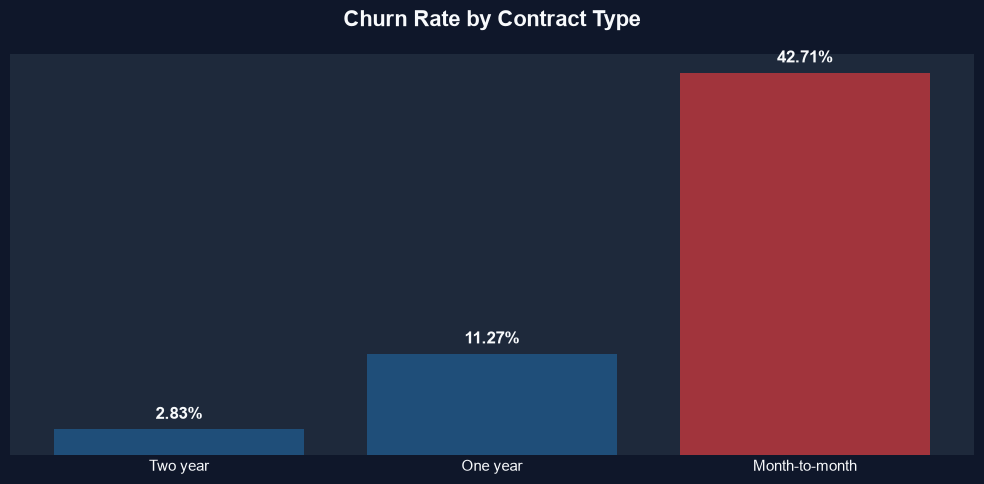

In [27]:
# ============================================================
# CELL 15 — CONTRACT CHURN CHART
# ============================================================

# ------------------------------------------------------------
# SORT BY CHURN RATE
# ------------------------------------------------------------

contract_churn = contract_churn.sort_values(
    "churn_rate",
    ascending=True
)

# ------------------------------------------------------------
# STANDARD COLORS
# Highest churn = Red
# Other contracts = Dark Blue
# ------------------------------------------------------------

Max_Churn_Index = contract_churn["churn_rate"].idxmax()

Bar_Colors = [
    "#A1343C" if index == Max_Churn_Index else "#1F4E79"
    for index in contract_churn.index
]

# ------------------------------------------------------------
# CHART
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

ax = plt.gca()

bars = ax.bar(
    contract_churn["contract"],
    contract_churn["churn_rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Churn Rate by Contract Type",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# ------------------------------------------------------------
# AXIS
# ------------------------------------------------------------

ax.set_xlabel("")
ax.set_ylabel("")

# Remove Y-axis numbers
ax.set_yticks([])

# ------------------------------------------------------------
# REMOVE GRID & BORDERS
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# ------------------------------------------------------------
# VALUES ABOVE BARS
# ------------------------------------------------------------

for bar, rate in zip(
    bars,
    contract_churn["churn_rate"]
):

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CHURN RATE BY INTERNET SERVICE
# ============================================================

internet_churn = (
    df.groupby("internetservice")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
    .sort_values("churn_rate", ascending=False)
)

internet_churn.round(2)

,internetservice,churn_rate
1,Fiber optic,41.89
0,DSL,18.96
2,No,7.40


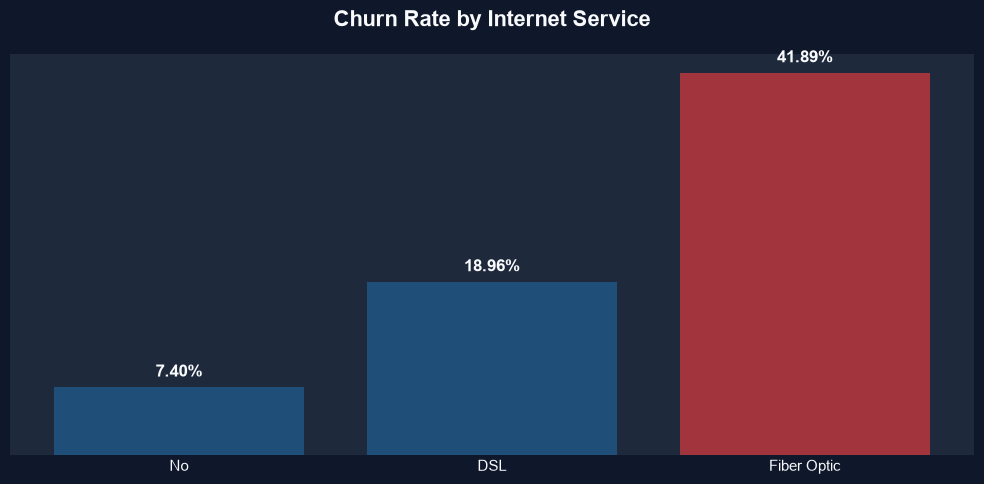

In [ ]:
# ============================================================
# CHURN RATE BY INTERNET SERVICE - CHART
# ============================================================

# Calculate churn rate by internet service
internet_churn = (
    df.groupby("internetservice")
      .agg(
          Customers=("customerid", "count"),
          Churned=("churn", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

internet_churn["Churn_Rate"] = (
    internet_churn["Churned"]
    / internet_churn["Customers"]
    * 100
)

# Display labels
internet_churn["InternetService_Display"] = (
    internet_churn["internetservice"]
    .astype(str)
    .str.strip()
    .replace({
        "dsl": "DSL",
        "DSL": "DSL",
        "fiber optic": "Fiber Optic",
        "Fiber optic": "Fiber Optic",
        "no": "No",
        "No": "No"
    })
)

# Sort from lowest to highest
internet_churn = internet_churn.sort_values(
    "Churn_Rate",
    ascending=True
)

# Highest churn = red
Max_Churn_Index = internet_churn["Churn_Rate"].idxmax()

Bar_Colors = [
    "#A1343C" if index == Max_Churn_Index else "#1F4E79"
    for index in internet_churn.index
]

# ============================================================
# CHART
# ============================================================

plt.figure(figsize=(10, 5))
ax = plt.gca()

bars = ax.bar(
    internet_churn["InternetService_Display"],
    internet_churn["Churn_Rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

# Title
ax.set_title(
    "Churn Rate by Internet Service",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# Clean design
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# Values above bars
for bar, rate in zip(
    bars,
    internet_churn["Churn_Rate"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# ONLINE SECURITY
# ============================================================

security_churn = (
    df.groupby("onlinesecurity")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
    .sort_values("churn_rate", ascending=False)
)

security_churn.round(2)

,onlinesecurity,churn_rate
0,No,41.77
2,Yes,14.61
1,No internet service,7.40


In [36]:
# ============================================================
# TECH SUPPORT
# ============================================================

support_churn = (
    df.groupby("techsupport")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
    .sort_values("churn_rate", ascending=False)
)

support_churn.round(2)

,techsupport,churn_rate
0,No,41.64
2,Yes,15.17
1,No internet service,7.40


In [ ]:
# ============================================================
# STREAMING SERVICES
# ============================================================

streaming_analysis = pd.DataFrame({
    "StreamingTV": (
        df.groupby("streamingtv")["churn"]
        .apply(lambda x: (x == "yes").mean() * 100)
    ),
    "StreamingMovies": (
        df.groupby("streamingmovies")["churn"]
        .apply(lambda x: (x == "yes").mean() * 100)
    )
})

streaming_analysis.round(2)

,StreamingTV,StreamingMovies
No,33.52,33.68
No internet service,7.40,7.40
Yes,30.07,29.94


In [38]:
# ============================================================
# PAYMENT METHOD ANALYSIS
# ============================================================

payment_churn = (
    df.groupby("paymentmethod")["churn"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index(name="churn_rate")
    .sort_values("churn_rate", ascending=False)
)

payment_churn.round(2)

,paymentmethod,churn_rate
2,Electronic check,45.29
3,Mailed check,19.11
0,Bank transfer (automatic),16.71
1,Credit card (automatic),15.24


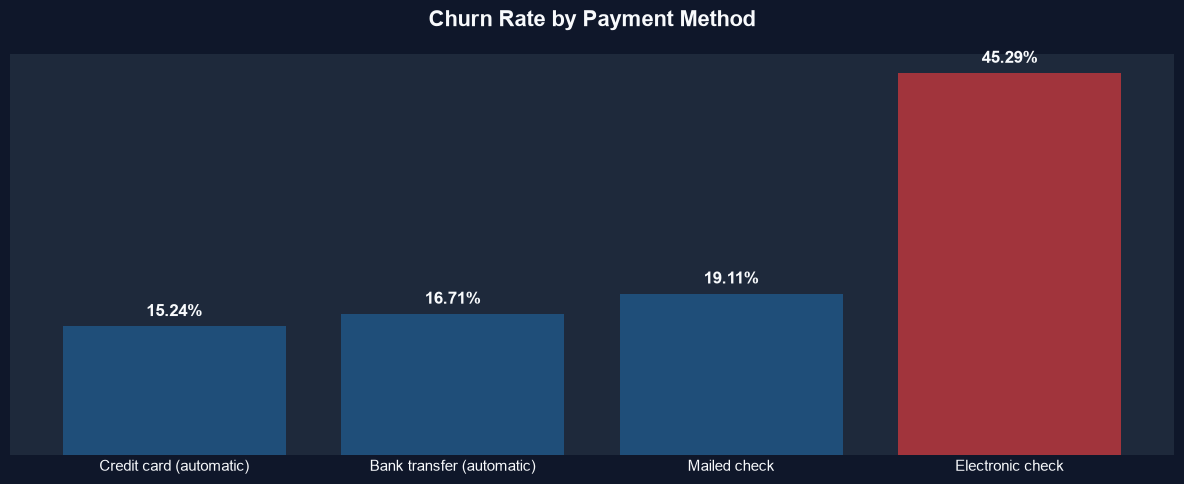

In [39]:
# ============================================================
# PAYMENT METHOD CHURN - CHART
# ============================================================

# Calculate churn rate by payment method
payment_churn = (
    df.groupby("paymentmethod")
      .agg(
          Customers=("customerid", "count"),
          Churned=("churn", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

payment_churn["Churn_Rate"] = (
    payment_churn["Churned"]
    / payment_churn["Customers"]
    * 100
)

# Display labels
payment_churn["PaymentMethod_Display"] = (
    payment_churn["paymentmethod"]
    .astype(str)
    .str.strip()
    .replace({
        "electronic check": "Electronic Check",
        "mailed check": "Mailed Check",
        "bank transfer (automatic)": "Bank Transfer (Automatic)",
        "credit card (automatic)": "Credit Card (Automatic)"
    })
)

# Sort from lowest to highest churn
payment_churn = payment_churn.sort_values(
    "Churn_Rate",
    ascending=True
)

# Highest churn = red
Max_Churn_Index = payment_churn["Churn_Rate"].idxmax()

Bar_Colors = [
    "#A1343C" if index == Max_Churn_Index else "#1F4E79"
    for index in payment_churn.index
]

# ============================================================
# CHART
# ============================================================

plt.figure(figsize=(12, 5))
ax = plt.gca()

bars = ax.bar(
    payment_churn["PaymentMethod_Display"],
    payment_churn["Churn_Rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

# Title
ax.set_title(
    "Churn Rate by Payment Method",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# Clean design
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# Values above bars
for bar, rate in zip(
    bars,
    payment_churn["Churn_Rate"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12,
        fontweight="bold"
    )

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# TENURE ANALYSIS
# ============================================================

tenure_stats = df["tenure"].describe()

tenure_stats

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [ ]:
# ============================================================
# TENURE ANALYSIS
# ============================================================

tenure_stats = df["tenure"].describe()

tenure_stats

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

In [ ]:
# ============================================================
# TENURE BY CHURN
# ============================================================

tenure_by_churn = (
    df.groupby("churn")["tenure"]
    .agg(["count", "mean", "median", "min", "max"])
)

tenure_by_churn.round(2)

,count,mean,median,min,max
churn,,,,,
no,5174,37.57,38.0,0,72
yes,1869,17.98,10.0,1,72


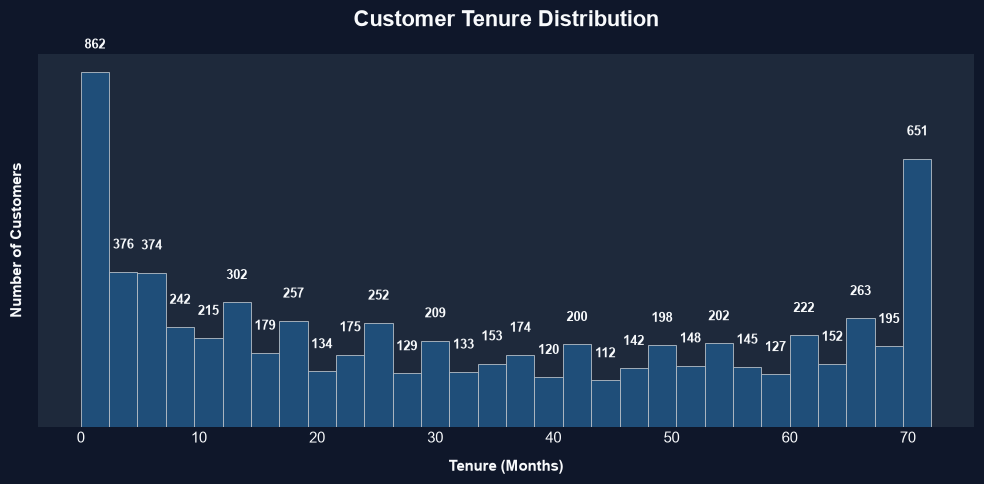

In [ ]:
# ============================================================
# CUSTOMER TENURE DISTRIBUTION
# ============================================================

plt.figure(figsize=(10, 5))
ax = plt.gca()

# Histogram
counts, bins, patches = ax.hist(
    df["tenure"],
    bins=30,
    color="#1F4E79",
    edgecolor="#B8C0C8",
    linewidth=0.6
)

# Title
ax.set_title(
    "Customer Tenure Distribution",
    fontsize=16,
    fontweight="bold",
    pad=20
)

# Axis labels
ax.set_xlabel(
    "Tenure (Months)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Number of Customers",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

# Hide Y-axis numbers but keep Y-axis title
ax.set_yticks([])

# Clean design
ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# Values above bars
for count, patch in zip(counts, patches):
    if count > 0:
        ax.text(
            patch.get_x() + patch.get_width() / 2,
            count + 50,
            f"{int(count):,}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

plt.tight_layout()
plt.show()

In [47]:
# ============================================================
# TENURE GROUP CREATION
# ============================================================

df["Tenure_Group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=[
        "0–12 Months",
        "13–24 Months",
        "25–36 Months",
        "37–48 Months",
        "49–60 Months",
        "61–72 Months"
    ],
    right=True
)

# Check distribution
tenure_group_summary = (
    df["Tenure_Group"]
    .value_counts(sort=False)
    .reset_index()
)

tenure_group_summary.columns = [
    "Tenure_Group",
    "Customers"
]

tenure_group_summary

,Tenure_Group,Customers
0,0–12 Months,2186
1,13–24 Months,1024
2,25–36 Months,832
3,37–48 Months,762
4,49–60 Months,832
5,61–72 Months,1407


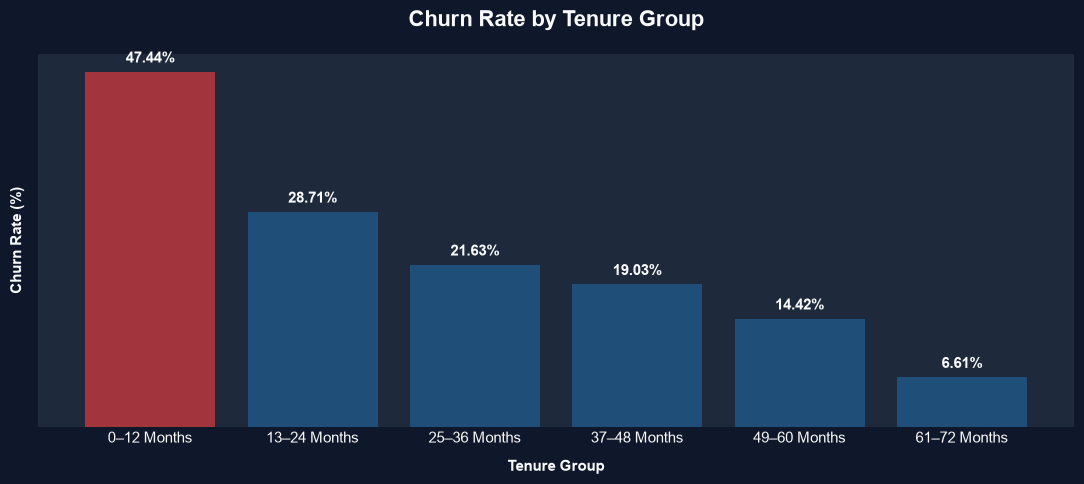

In [48]:
# ============================================================
# CHURN RATE BY TENURE GROUP
# ============================================================

tenure_churn = (
    df.groupby("Tenure_Group", observed=False)
      .agg(
          Customers=("customerid", "count"),
          Churned=("churn", lambda x: (x == "yes").sum())
      )
      .reset_index()
)

tenure_churn["Churn_Rate"] = (
    tenure_churn["Churned"]
    / tenure_churn["Customers"]
    * 100
)

# Highest churn group = red
Max_Churn_Index = tenure_churn["Churn_Rate"].idxmax()

Bar_Colors = [
    "#A1343C" if index == Max_Churn_Index else "#1F4E79"
    for index in tenure_churn.index
]

# ============================================================
# CHART
# ============================================================

plt.figure(figsize=(11, 5))
ax = plt.gca()

bars = ax.bar(
    tenure_churn["Tenure_Group"].astype(str),
    tenure_churn["Churn_Rate"],
    color=Bar_Colors,
    edgecolor="none",
    linewidth=0
)

ax.set_title(
    "Churn Rate by Tenure Group",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Tenure Group",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

ax.set_ylabel(
    "Churn Rate (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10
)

# Hide Y-axis numbers
ax.set_yticks([])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0
)

# Percentage above bars
for bar, rate in zip(
    bars,
    tenure_churn["Churn_Rate"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.8,
        f"{rate:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

C:\Users\Kunde\AppData\Local\Temp\ipykernel_16872\1343891539.py:47: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([


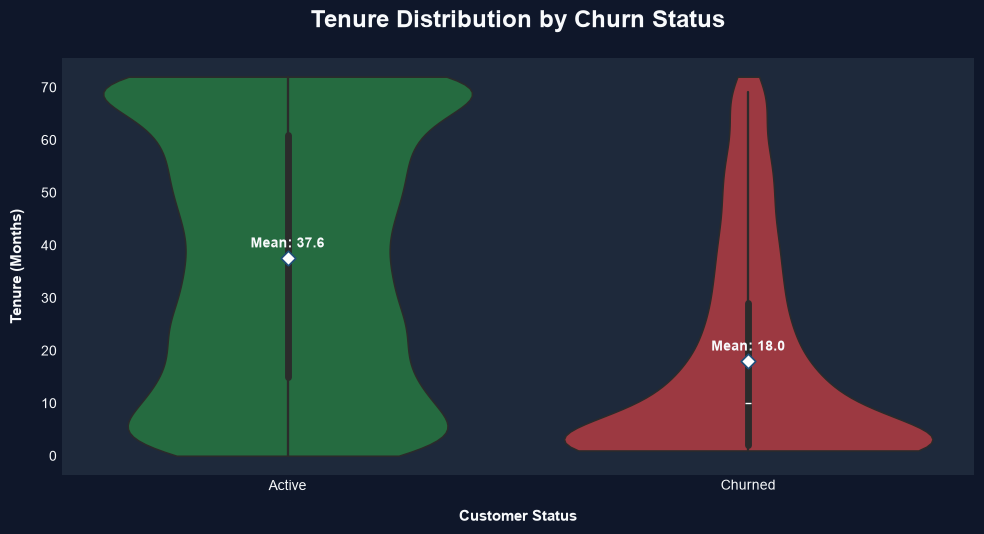

In [55]:
# ============================================================
# TENURE VS CHURN
# Professional Seaborn Violin Plot
# ============================================================

plt.figure(figsize=(10, 5.5))

ax = sns.violinplot(
    data=df,
    x="churn",
    y="tenure",
    hue="churn",
    order=["no", "yes"],
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    inner="box",
    cut=0,
    linewidth=1.1,
    saturation=0.90,
    legend=False
)

ax.set_title(
    "Tenure Distribution by Churn Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Tenure (Months)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels([
    "Active",
    "Churned"
])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

# Mean
means = [
    df.loc[df["churn"] == "no", "tenure"].mean(),
    df.loc[df["churn"] == "yes", "tenure"].mean()
]

for x, mean in enumerate(means):

    ax.scatter(
        x,
        mean,
        marker="D",
        s=55,
        color="#FFFFFF",
        edgecolor="#1F4E79",
        linewidth=1.2,
        zorder=5
    )

    ax.text(
        x,
        mean + 2,
        f"Mean: {mean:.1f}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

C:\Users\Kunde\AppData\Local\Temp\ipykernel_16872\548109729.py:60: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([


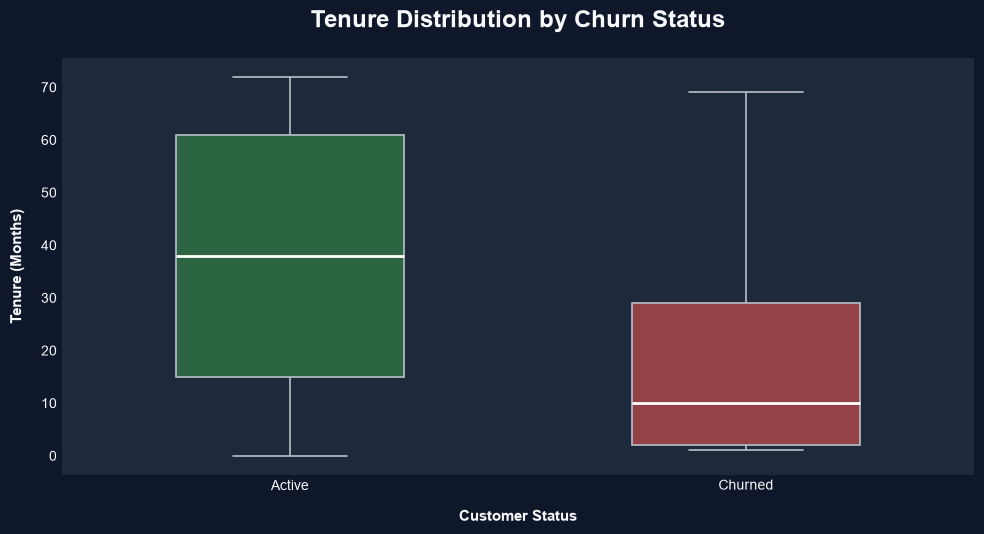

In [56]:
# ============================================================
# TENURE — BOX PLOT
# ============================================================

plt.figure(figsize=(10, 5.5))

ax = sns.boxplot(
    data=df,
    x="churn",
    y="tenure",
    hue="churn",
    order=["no", "yes"],
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    width=0.50,
    showfliers=False,
    linewidth=1.2,
    boxprops={
        "edgecolor": "#B8C0C8"
    },
    whiskerprops={
        "color": "#B8C0C8",
        "linewidth": 1.2
    },
    capprops={
        "color": "#B8C0C8",
        "linewidth": 1.2
    },
    medianprops={
        "color": "#FFFFFF",
        "linewidth": 2
    },
    legend=False
)

ax.set_title(
    "Tenure Distribution by Churn Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Tenure (Months)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels([
    "Active",
    "Churned"
])

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()

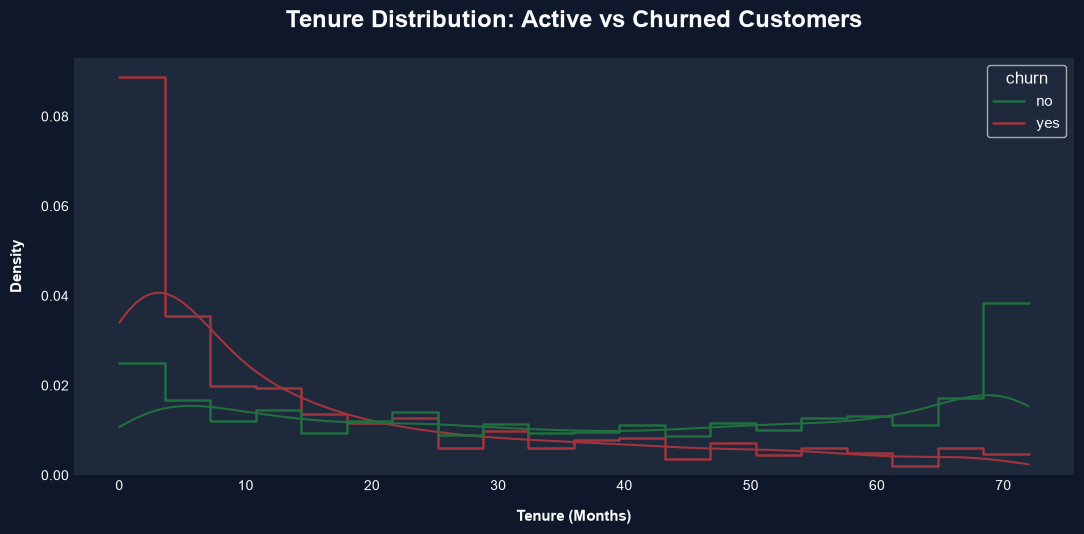

In [57]:
# ============================================================
# TENURE — HISTOGRAM + KDE
# ============================================================

plt.figure(figsize=(11, 5.5))

ax = sns.histplot(
    data=df,
    x="tenure",
    hue="churn",
    hue_order=["no", "yes"],
    bins=20,
    kde=True,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    linewidth=1.8
)

ax.set_title(
    "Tenure Distribution: Active vs Churned Customers",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Tenure (Months)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Density",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()

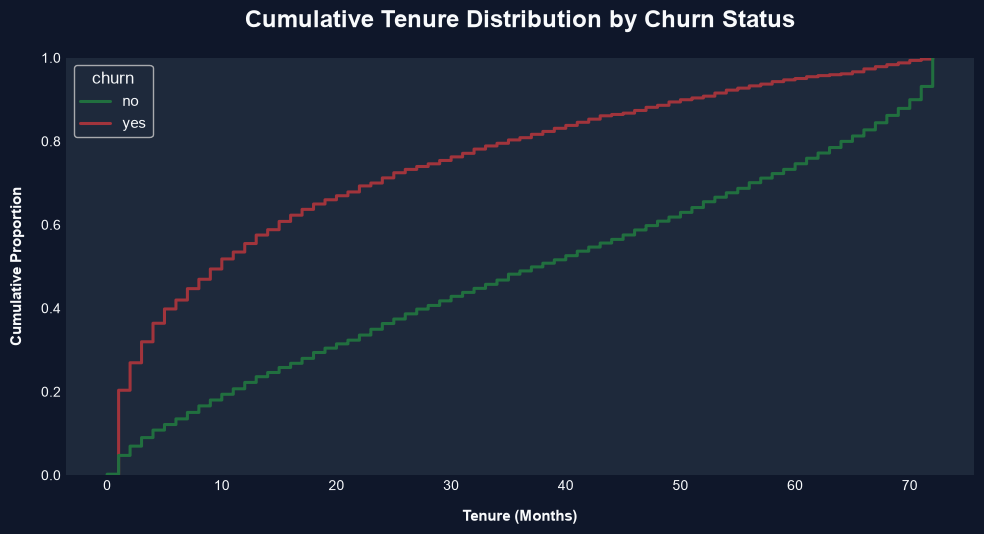

In [58]:
# ============================================================
# TENURE — ECDF PLOT
# ============================================================

plt.figure(figsize=(10, 5.5))

ax = sns.ecdfplot(
    data=df,
    x="tenure",
    hue="churn",
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    linewidth=2.2
)

ax.set_title(
    "Cumulative Tenure Distribution by Churn Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Tenure (Months)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Cumulative Proportion",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()

In [60]:
# ============================================================
# MONTHLY CHARGES ANALYSIS
# ============================================================

monthly_stats = df["monthlycharges"].describe()

monthly_stats.round(2)

count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75
Name: monthlycharges, dtype: float64

In [63]:
# ============================================================
# MONTHLY CHARGES BY CHURN
# ============================================================

monthly_by_churn = (
    df.groupby("churn")["monthlycharges"]
    .agg(["count", "mean", "median", "min", "max"])
)

monthly_by_churn.round(2)

,count,mean,median,min,max
churn,,,,,
no,5174,61.27,64.43,18.25,118.75
yes,1869,74.44,79.65,18.85,118.35


C:\Users\Kunde\AppData\Local\Temp\ipykernel_16872\1489595352.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([


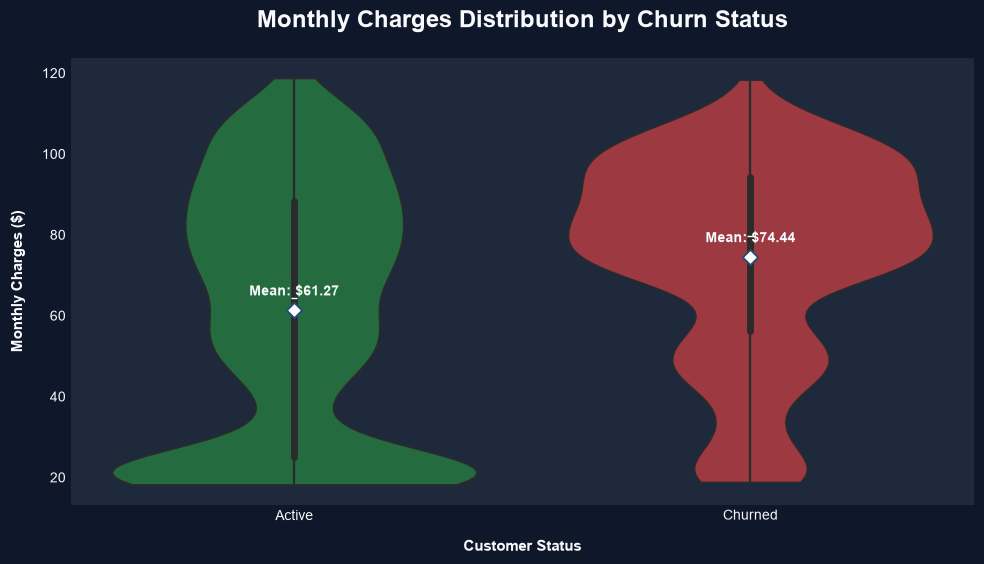

In [ ]:
# ============================================================
# MONTHLY CHARGES VS CHURN
# Professional Violin + Box + Mean
# ============================================================

plt.figure(figsize=(10, 5.8))

ax = sns.violinplot(
    data=df,
    x="churn",
    y="monthlycharges",
    hue="churn",
    order=["no", "yes"],
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    inner="box",
    cut=0,
    linewidth=1.1,
    saturation=0.90,
    legend=False
)

# ------------------------------------------------------------
# MEAN VALUES
# ------------------------------------------------------------

mean_values = [
    df.loc[df["churn"] == "no", "monthlycharges"].mean(),
    df.loc[df["churn"] == "yes", "monthlycharges"].mean()
]

for x, mean in enumerate(mean_values):

    ax.scatter(
        x,
        mean,
        marker="D",
        s=60,
        color="#FFFFFF",
        edgecolor="#1F4E79",
        linewidth=1.3,
        zorder=5
    )

    ax.text(
        x,
        mean + 3,
        f"Mean:  ${mean:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Monthly Charges Distribution by Churn Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Monthly Charges ($)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels([
    "Active",
    "Churned"
])

# ------------------------------------------------------------
# PROFESSIONAL STYLE
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# TOTAL CHARGES ANALYSIS
# ============================================================

total_stats = df["totalcharges"].describe()

total_stats.round(2)

count    7043.00
mean     2279.73
std      2266.79
min         0.00
25%       398.55
50%      1394.55
75%      3786.60
max      8684.80
Name: totalcharges, dtype: float64

C:\Users\Kunde\AppData\Local\Temp\ipykernel_16872\1808641398.py:87: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([


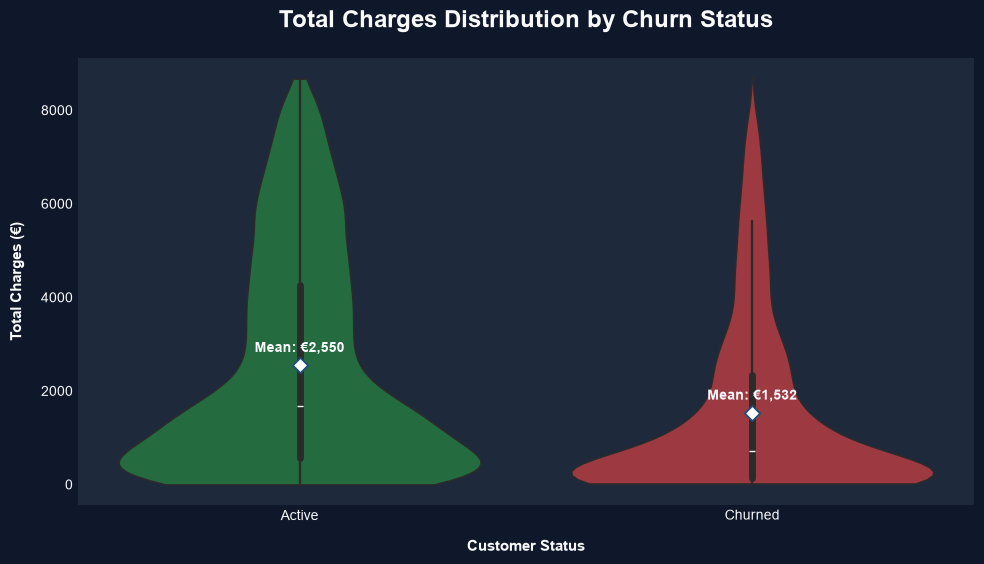

In [ ]:
# ============================================================
# TOTAL CHARGES BY CHURN
# Professional Violin + Box + Mean
# ============================================================

plt.figure(figsize=(10, 5.8))

ax = sns.violinplot(
    data=df,
    x="churn",
    y="totalcharges",
    hue="churn",
    order=["no", "yes"],
    hue_order=["no", "yes"],
    palette={
        "no": "#216F3F",
        "yes": "#A1343C"
    },
    inner="box",
    cut=0,
    linewidth=1.1,
    saturation=0.90,
    legend=False
)

# ------------------------------------------------------------
# MEAN VALUES
# ------------------------------------------------------------

mean_values = [
    df.loc[df["churn"] == "no", "totalcharges"].mean(),
    df.loc[df["churn"] == "yes", "totalcharges"].mean()
]

for x, mean in enumerate(mean_values):

    ax.scatter(
        x,
        mean,
        marker="D",
        s=60,
        color="#FFFFFF",
        edgecolor="#1F4E79",
        linewidth=1.3,
        zorder=5
    )

    ax.text(
        x,
        mean + (df["totalcharges"].max() * 0.025),
        f"Mean: €{mean:,.0f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Total Charges Distribution by Churn Status",
    fontsize=17,
    fontweight="bold",
    pad=22
)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Customer Status",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Total Charges (€)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_xticklabels([
    "Active",
    "Churned"
])

# ------------------------------------------------------------
# PROFESSIONAL STYLE
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# TOTAL CHARGES STATISTICAL SUMMARY
# ============================================================

total_by_churn = (
    df.groupby("churn")["totalcharges"]
    .agg(
        Customers="count",
        Mean="mean",
        Median="median",
        Minimum="min",
        Maximum="max"
    )
)

total_by_churn.round(2)

,Customers,Mean,Median,Minimum,Maximum
churn,,,,,
no,5174,2549.91,1679.52,0.00,8672.45
yes,1869,1531.80,703.55,18.85,8684.80


In [ ]:
# ============================================================
# TOTAL CHARGES BY CHURN
# ============================================================

total_by_churn = (
    df.groupby("churn")["totalcharges"]
    .agg(["count", "mean", "median", "min", "max"])
)

total_by_churn.round(2)

,count,mean,median,min,max
churn,,,,,
no,5174,2549.91,1679.52,0.00,8672.45
yes,1869,1531.80,703.55,18.85,8684.80


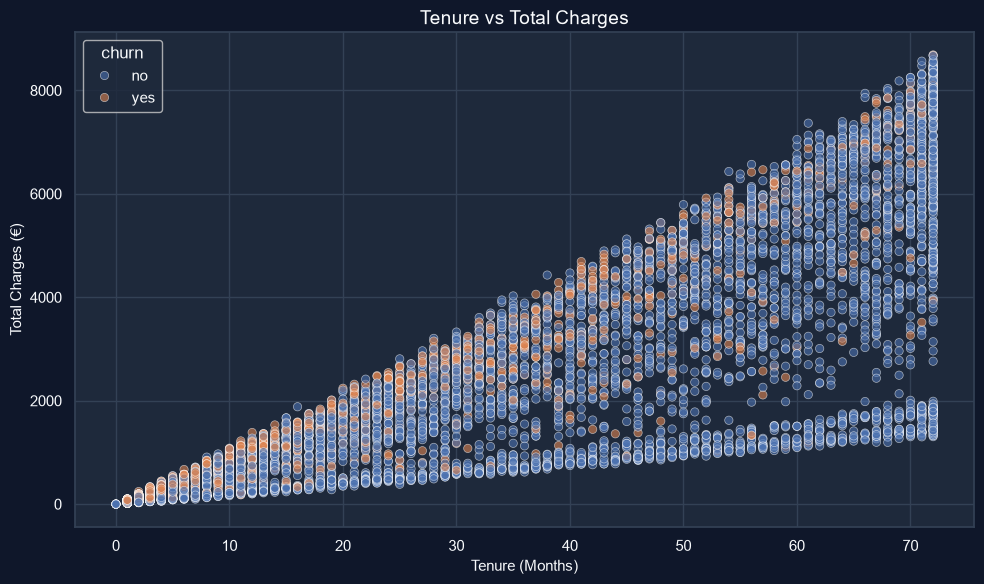

In [71]:
# ============================================================
# MONTHLY VS TOTAL CHARGES
# ============================================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="tenure",
    y="totalcharges",
    hue="churn",
    alpha=0.6
)

plt.title("Tenure vs Total Charges")
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Charges (€)")

plt.tight_layout()
plt.show()

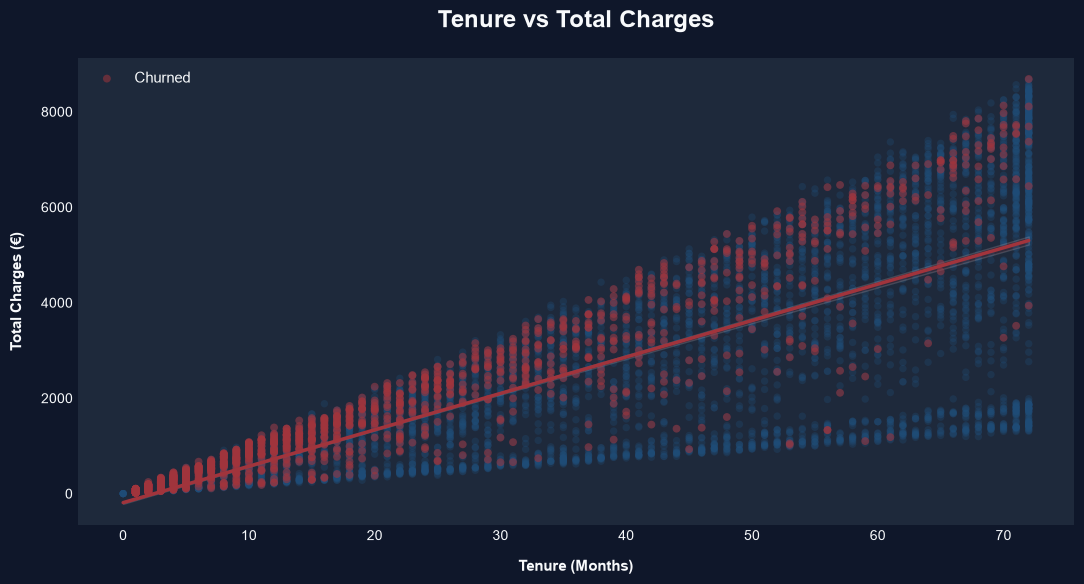

In [74]:
# ============================================================
# CELL 32 — TENURE VS TOTAL CHARGES
# Professional Scatter Plot + Regression
# ============================================================

plt.figure(figsize=(11, 6))

ax = sns.regplot(
    data=df,
    x="tenure",
    y="totalcharges",
    scatter_kws={
        "alpha": 0.30,
        "s": 28,
        "color": "#1F4E79",
        "edgecolor": "none"
    },
    line_kws={
        "color": "#A1343C",
        "linewidth": 2.5}
)

# ------------------------------------------------------------
# CHURNED CUSTOMERS — HIGHLIGHT
# ------------------------------------------------------------

churned = df[df["churn"] == "yes"]

ax.scatter(
    churned["tenure"],
    churned["totalcharges"],
    s=32,
    alpha=0.55,
    color="#A1343C",
    edgecolor="none",
    label="Churned"
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Tenure vs Total Charges",
    fontsize=17,
    fontweight="bold",
    pad=22
)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Tenure (Months)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Total Charges (€)",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

# ------------------------------------------------------------
# LEGEND
# ------------------------------------------------------------

ax.legend(
    frameon=False,
    loc="upper left"
)

# ------------------------------------------------------------
# PROFESSIONAL STYLE
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.tight_layout()
plt.show()

In [77]:
# ============================================================
# SERVICE USAGE OVERVIEW
# ============================================================

service_columns = [
    "phoneservice",
    "onlinesecurity",
    "onlinebackup",
    "deviceprotection",
    "techsupport",
    "streamingtv",
    "streamingmovies"
]

service_usage = {}

for column in service_columns:
    service_usage[column] = (
        df[column]
        .astype(str)
        .str.lower()
        .eq("yes")
        .sum()
    )

service_usage = pd.Series(service_usage)

service_usage

phoneservice        6361
onlinesecurity      2019
onlinebackup        2429
deviceprotection    2422
techsupport         2044
streamingtv         2707
streamingmovies     2732
dtype: int64

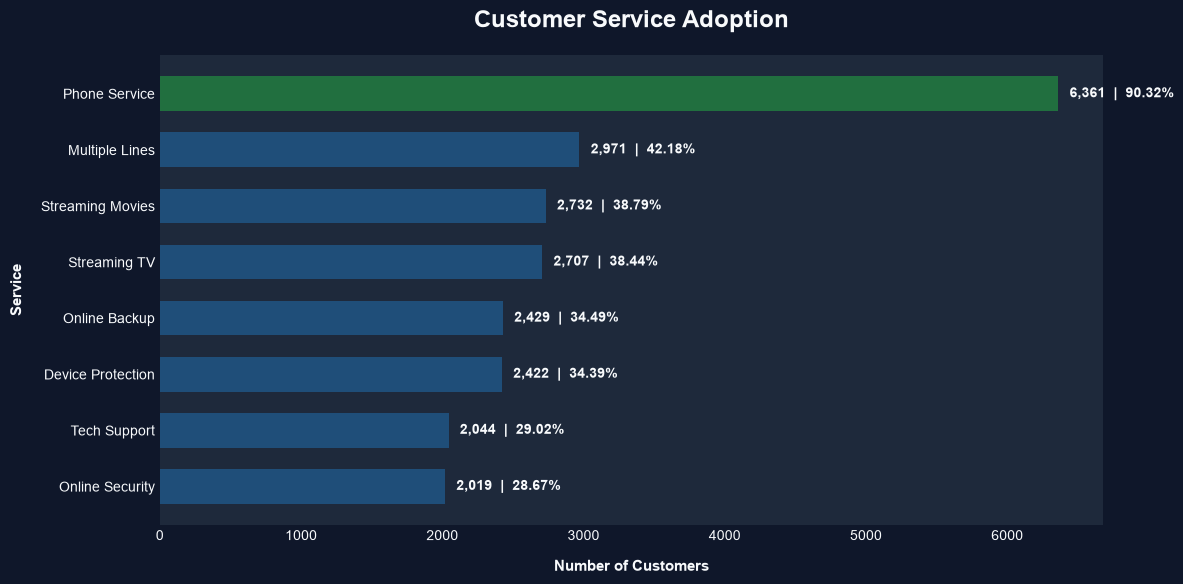

In [ ]:
# ============================================================
# SERVICE USAGE
# Professional Horizontal Bar Chart
# ============================================================

# ------------------------------------------------------------
# SERVICE DATA
# ------------------------------------------------------------

service_usage = pd.Series({
    "Phone Service": (df["phoneservice"] == "Yes").sum(),
    "Multiple Lines": (df["multiplelines"] == "Yes").sum(),
    "Online Security": (df["onlinesecurity"] == "Yes").sum(),
    "Online Backup": (df["onlinebackup"] == "Yes").sum(),
    "Device Protection": (df["deviceprotection"] == "Yes").sum(),
    "Tech Support": (df["techsupport"] == "Yes").sum(),
    "Streaming TV": (df["streamingtv"] == "Yes").sum(),
    "Streaming Movies": (df["streamingmovies"] == "Yes").sum()
})

service_usage = service_usage.sort_values(ascending=True)

total_customers = len(df)

service_df = pd.DataFrame({
    "Service": service_usage.index,
    "Customers": service_usage.values
})

service_df["Adoption_Rate"] = (
    service_df["Customers"]
    / total_customers
    * 100
)

# ------------------------------------------------------------
# COLORS
# Highest adoption = green
# ------------------------------------------------------------

max_index = service_df["Customers"].idxmax()

bar_colors = [
    "#216F3F" if index == max_index else "#1F4E79"
    for index in service_df.index
]

# ------------------------------------------------------------
# CHART
# ------------------------------------------------------------

plt.figure(figsize=(12, 6))

ax = plt.gca()

bars = ax.barh(
    service_df["Service"],
    service_df["Customers"],
    color=bar_colors,
    edgecolor="none",
    height=0.62
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Customer Service Adoption",
    fontsize=17,
    fontweight="bold",
    pad=20
)

# ------------------------------------------------------------
# AXIS LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of Customers",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Service",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

# ------------------------------------------------------------
# AXIS STYLE
# ------------------------------------------------------------

ax.grid(False)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

# ------------------------------------------------------------
# DATA LABELS
# ------------------------------------------------------------

for bar, customers, rate in zip(
    bars,
    service_df["Customers"],
    service_df["Adoption_Rate"]
):

    ax.text(
        bar.get_width() + 80,
        bar.get_y() + bar.get_height() / 2,
        f"{customers:,}  |  {rate:.2f}%",
        va="center",
        fontsize=10,
        fontweight="bold"
    )

# ------------------------------------------------------------
# LAYOUT
# ------------------------------------------------------------

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# MULTIPLE LINES ANALYSIS
# ============================================================

multiplelines_churn = (
    df.groupby("multiplelines")["churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .reset_index(name="churn_rate")
)

# Robust lowercase version
multiplelines_churn = (
    df.assign(
        churn_flag=df["churn"].str.lower().eq("yes")
    )
    .groupby("multiplelines")["churn_flag"]
    .mean()
    .mul(100)
    .reset_index(name="churn_rate")
)

multiplelines_churn.round(2)

,multiplelines,churn_rate
0,No,25.04
1,No phone service,24.93
2,Yes,28.61


In [ ]:
# ============================================================
# PAPERLESS BILLING
# ============================================================

paperless_churn = (
    df.assign(
        churn_flag=df["churn"].str.lower().eq("yes")
    )
    .groupby("paperlessbilling")["churn_flag"]
    .mean()
    .mul(100)
    .reset_index(name="churn_rate")
)

paperless_churn.round(2)

,paperlessbilling,churn_rate
0,No,16.33
1,Yes,33.57


In [81]:
# ============================================================
# NUMERICAL CORRELATION
# ============================================================

numeric_columns = [
    "seniorcitizen",
    "tenure",
    "monthlycharges",
    "totalcharges"
]

correlation_matrix = (
    df[numeric_columns]
    .corr()
)

correlation_matrix.round(2)

,seniorcitizen,tenure,monthlycharges,totalcharges
seniorcitizen,1.00,0.02,0.22,0.10
tenure,0.02,1.00,0.25,0.83
monthlycharges,0.22,0.25,1.00,0.65
totalcharges,0.10,0.83,0.65,1.00


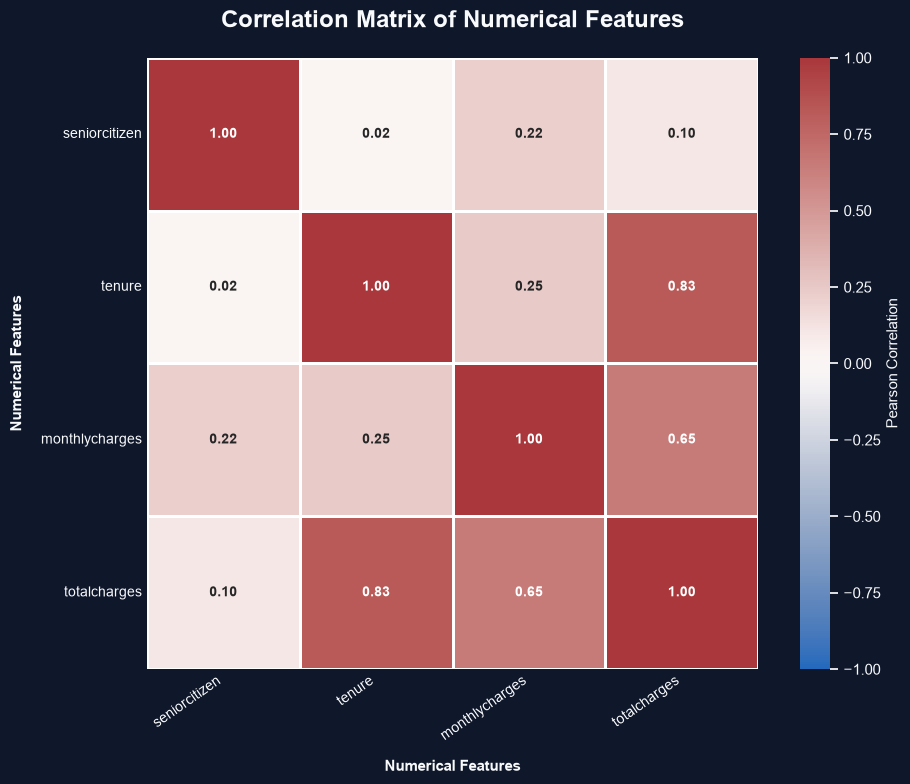

In [ ]:
# ============================================================
# CORRELATION HEATMAP
# Professional Statistical Visualization
# ============================================================

plt.figure(figsize=(10, 8))

ax = sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "Pearson Correlation"
    },
    annot_kws={
        "fontsize": 10,
        "fontweight": "bold"
    }
)

ax.set_title(
    "Correlation Matrix of Numerical Features",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel(
    "Numerical Features",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    "Numerical Features",
    fontsize=11,
    fontweight="bold",
    labelpad=12
)

ax.tick_params(
    axis="both",
    length=0,
    labelsize=10
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [84]:
# ============================================================
# KEY CHURN DRIVERS
# ============================================================

churn_drivers = {}

analysis_columns = [
    "gender",
    "seniorcitizen",
    "partner",
    "dependents",
    "contract",
    "internetservice",
    "onlinesecurity",
    "onlinebackup",
    "deviceprotection",
    "techsupport",
    "paymentmethod",
    "paperlessbilling"
]

for column in analysis_columns:

    churn_drivers[column] = (
        df.assign(
            churn_flag=df["churn"].str.lower().eq("yes")
        )
        .groupby(column)["churn_flag"]
        .mean()
        .mul(100)
        .max()
    )

driver_summary = (
    pd.Series(churn_drivers)
    .sort_values(ascending=False)
    .to_frame("Highest_Group_Churn_Rate")
)

driver_summary.round(2)

,Highest_Group_Churn_Rate
paymentmethod,45.29
contract,42.71
internetservice,41.89
onlinesecurity,41.77
seniorcitizen,41.68
techsupport,41.64
onlinebackup,39.93
deviceprotection,39.13
paperlessbilling,33.57
partner,32.96


In [ ]:
# ============================================================
# FINAL EDA SUMMARY
# ============================================================

overall_churn = (
    df["churn"].str.lower().eq("yes").mean() * 100
)

avg_tenure = df["tenure"].mean()

avg_monthly = df["monthlycharges"].mean()

total_revenue = df["totalcharges"].sum()

print("=" * 70)
print("CUSTOMER CHURN ANALYTICS — EDA SUMMARY")
print("=" * 70)

print(f"Total Customers       : {len(df):,}")
print(f"Churned Customers     : {df['churn'].str.lower().eq('yes').sum():,}")
print(f"Overall Churn Rate    : {overall_churn:.2f}%")
print(f"Average Tenure        : {avg_tenure:.2f} months")
print(f"Average Monthly Charge: €{avg_monthly:.2f}")
print(f"Total Customer Revenue: €{total_revenue:,.2f}")

print("=" * 70)

CUSTOMER CHURN ANALYTICS — EDA SUMMARY
Total Customers       : 7,043
Churned Customers     : 1,869
Overall Churn Rate    : 26.54%
Average Tenure        : 32.37 months
Average Monthly Charge: €64.76
Total Customer Revenue: €16,056,168.70


In [86]:
# ============================================================
# SAVE EDA TABLES
# ============================================================

OUTPUT_DIR = Path("../outputs/tables")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

churn_summary.to_csv(
    OUTPUT_DIR / "churn_summary.csv"
)

contract_churn.to_csv(
    OUTPUT_DIR / "contract_churn.csv",
    index=False
)

internet_churn.to_csv(
    OUTPUT_DIR / "internet_churn.csv",
    index=False
)

payment_churn.to_csv(
    OUTPUT_DIR / "payment_churn.csv",
    index=False
)

tenure_by_churn.to_csv(
    OUTPUT_DIR / "tenure_by_churn.csv"
)

monthly_by_churn.to_csv(
    OUTPUT_DIR / "monthly_charges_by_churn.csv"
)

total_by_churn.to_csv(
    OUTPUT_DIR / "total_charges_by_churn.csv"
)

print("EDA tables saved successfully.")

EDA tables saved successfully.


In [ ]:
# ============================================================
# FINAL EDA VALIDATION
# ============================================================

print("=" * 70)
print("FINAL EDA VALIDATION")
print("=" * 70)

print(f"Dataset Rows        : {len(df):,}")
print(f"Dataset Columns     : {len(df.columns):,}")
print(f"Missing Values      : {df.isna().sum().sum():,}")
print(f"Duplicate Rows      : {df.duplicated().sum():,}")
print(f"Unique Customers    : {df['customerid'].nunique():,}")
print(f"Churn Rate          : {overall_churn:.2f}%")

print("=" * 70)

FINAL EDA VALIDATION
Dataset Rows        : 7,043
Dataset Columns     : 22
Missing Values      : 0
Duplicate Rows      : 0
Unique Customers    : 7,043
Churn Rate          : 26.54%
